**Web Scraping (Data Collection)**

In [ ]:
import requests # Send HTTP requests to websites
from bs4 import BeautifulSoup # Parse and navigate HTML
# ─── Data Handling ────────────────────────────────────────────────
import pandas as pd
import numpy as np
import csv # Save to CSV files
import json # Save to JSON files
# ─── Utilities ────────────────────────────────────────────────────
import time # Pause between requests
import re # Regular expressions for text cleaning
print("✅")

In [ ]:
url = "https://center.cruises/cruises-sea/"

response = requests.get(url)
# ─── Check what we got back ───────────────────────────────────────
print(f"Status Code : {response.status_code}")
print(f"Content Type: {response.headers['Content-Type']}")
print(f"Page Size   : {len(response.text):,} characters")
if response.status_code == 200:
  print("✅ Page fetched successfully!")
  print(f"First 300 characters of HTML:\n")
  print(response.text[:300])

Status Code : 200
Content Type: text/html; charset=UTF-8
Page Size   : 192,553 characters
✅ Page fetched successfully!
First 300 characters of HTML:





<!DOCTYPE html>
<html lang="ru" dir="ltr">
    <head>
        
<!--     <script src="https://cdn.botpress.cloud/webchat/v3.2/inject.js" defer></script>-->
<!--    <script src="https://files.bpcontent.cloud/2025/08/03/13/20250803132231-ZYIQ7CYE.js" defer></script>-->

    <!-- Google Tag Manager 


In [ ]:
response = requests.get("https://center.cruises/cruises-sea/")
soup = BeautifulSoup(response.text, "html.parser")
# Parsers: "html.parser" (built-in), "lxml" (faster, install separately)
print(type(soup))
print("\nPage Title:", soup.title)
print("Title Text:", soup.title.text)

<class 'bs4.BeautifulSoup'>

Page Title: <title>Морские круизы купить круизный тур: цены, расписание, акции, бронь на 2026/2027/2028 год</title>
Title Text: Морские круизы купить круизный тур: цены, расписание, акции, бронь на 2026/2027/2028 год


In [ ]:
import requests
from bs4 import BeautifulSoup
import pandas as pd
import time

BASE_URL = "https://center.cruises/cruises-sea/"
MAX_PAGES = 1000

data = []

headers = {
    "User-Agent": "Mozilla/5.0"
}

def fetch_page(url, retries=3, timeout=10):
    for attempt in range(retries):
        try:
            response = requests.get(url, headers=headers, timeout=timeout)
            response.raise_for_status()
            return response
        except requests.exceptions.RequestException as e:
            print(f"⚠ Error: {e} (attempt {attempt+1}/{retries})")
            time.sleep(2)
    return None

for page_num in range(1, MAX_PAGES + 1):

    url = f"https://center.cruises/cruises-sea/page-{page_num}/"

    response = fetch_page(url)
    if response is None:
        print(f"❌ Failed to fetch page {page_num}, skipping...")
        continue

    soup = BeautifulSoup(response.text, "html.parser")

    all_divs = soup.find_all("div", class_="card border-0 mb-0 br-0")

    if not all_divs:
        print(f"⚠ No products found on page {page_num}, stopping.")
        break

    for d in all_divs:
        try:
            name_tag = d.find("h4", class_="font-weight-semibold2 mt-1 mb-2 leading-normal")
            name = name_tag.text.strip() if name_tag else None

            spans = d.select(".badge.badge-pill.border.mt-1.fs-12")
            ship = spans[0].get_text(strip=True) if len(spans) > 0 else None
            company = spans[1].get_text(strip=True) if len(spans) > 1 else None

            # Corrected line: removed garbled characters and fixed the unterminated string
            # NOTE: 'div' is a placeholder, you might need to adjust this to the correct tag and attributes to extract the date.
            date_tag = d.find("div", class_="your-actual-date-class") # Placeholder for the actual date element
            date = date_tag.text.strip() if date_tag else None

            day_tag = d.find("div", class_="mt-2 mb-0 text-dark d-block")
            duration = day_tag.text.strip() if day_tag else None

            price_tag = d.find("span", class_="text-dark")
            price = price_tag.text.strip() if price_tag else None


            data.append({
                "name": name,
                "ship": ship,
                "company": company,
                "date": date,
                "price": price,
                "duration": duration
            })

        except Exception as e:
            print(f"⚠ Error parsing product on page {page_num}: {e}")
            continue

    print(f"✅ Page {page_num} scraped — {len(all_divs)} cruises")
    time.sleep(0.5)


df = pd.DataFrame(data)

print(f"\n🎉 Total products scraped: {len(df)}")
print(df.head(10))

✅ Page 1 scraped — 20 cruises
✅ Page 2 scraped — 20 cruises
✅ Page 3 scraped — 20 cruises
✅ Page 4 scraped — 20 cruises
✅ Page 5 scraped — 20 cruises
✅ Page 6 scraped — 20 cruises
✅ Page 7 scraped — 20 cruises
✅ Page 8 scraped — 20 cruises
✅ Page 9 scraped — 20 cruises
✅ Page 10 scraped — 20 cruises
✅ Page 11 scraped — 20 cruises
✅ Page 12 scraped — 20 cruises
✅ Page 13 scraped — 20 cruises
✅ Page 14 scraped — 20 cruises
✅ Page 15 scraped — 20 cruises
✅ Page 16 scraped — 20 cruises
✅ Page 17 scraped — 20 cruises
✅ Page 18 scraped — 20 cruises
✅ Page 19 scraped — 20 cruises
✅ Page 20 scraped — 20 cruises
✅ Page 21 scraped — 20 cruises
✅ Page 22 scraped — 20 cruises
✅ Page 23 scraped — 20 cruises
✅ Page 24 scraped — 20 cruises
✅ Page 25 scraped — 20 cruises
✅ Page 26 scraped — 20 cruises
✅ Page 27 scraped — 20 cruises
✅ Page 28 scraped — 20 cruises
✅ Page 29 scraped — 20 cruises
✅ Page 30 scraped — 20 cruises
✅ Page 31 scraped — 20 cruises
✅ Page 32 scraped — 20 cruises
✅ Page 33 scraped

In [ ]:
df[['start_date', 'end_date']] = df['date'].str.split(' - ', expand=True)
df = df.drop("date", axis=1, errors="ignore")
df.head()

KeyError: 'date'

In [ ]:
df.to_csv("cruise.csv", index=False, encoding="utf-8-sig")

In [ ]:
import pandas as pd
df= pd.read_csv("/content/cruise (3).csv")

**Data Cleaning and Preprocessing**

In [ ]:
len(df)

20000

In [ ]:
df.isnull().sum()

,0
name,0
ship,0
company,0
price,0
duration,0
start_date,0
end_date,0


In [ ]:
df.shape

(20000, 7)

In [ ]:
print(df.duplicated().sum())
df.duplicated()

11457


,0
0,False
1,False
2,False
3,False
4,False
...,...
19995,True
19996,True
19997,True
19998,True


In [ ]:
df = df.drop_duplicates(keep='last')
df.head()

,name,ship,company,price,duration,start_date,end_date
10,"2 ночи Барселона, Канны, Чивитавеккья",Лайнер: MSC Divina,MSC Cruises,89€,2 ночи,ср 22 апр.,пт 24 апр.
11,"3 ночи Ливорно, Чивитавеккья, Валенсия",Лайнер: MSC Orchestra,MSC Cruises,439€,3 ночи,ср 22 апр.,сб 25 апр.
12,"5 ночей Франция, Италия, Испания",Лайнер: MSC Fantasia,MSC Cruises,449€,5 ночей,ср 22 апр.,пн 27 апр.
13,"2 ночи Барселона, Канны, Чивитавеккья",Лайнер: MSC Yacht Club Divina,MSC Yacht Club,569€,2 ночи,ср 22 апр.,пт 24 апр.
14,"Spain, Italy, France, Gibraltar, Portugal BCN1...",Лайнер: Costa Favolosa,Costa Cruises,699€,11 ночей,ср 22 апр.,вс 03 мая


In [ ]:
df.reset_index(drop=True, inplace=True)
df.head()

,name,ship,company,date,price,duration,destinations
0,"4 ночи Порт-Канаверал, Нассау, Оушен-Кей, Порт...",Лайнер: MSC Seashore,MSC Cruises,NaN,329€,4 ночи,"[Порт-Канаверал, Нассау, Оушен-Кей, Порт-Канав..."
1,"Italy, Spain, France SVN04A30",Лайнер: Costa Fascinosa,Costa Cruises,NaN,349€,4 ночи,"[Italy, Spain, France SVN04A30]"
2,"7 ночей Италия, Хорватия, Греция, Черногория",Лайнер: MSC Armonia,MSC Cruises,NaN,469€,7 ночей,"[Италия, Хорватия, Греция, Черногория]"
3,"4 ночи из Майами, Флорида",Лайнер: Symphony of the Seas,Royal Caribbean International,NaN,527€,4 ночи,"[из Майами, Флорида]"
4,"7 ночей Галвестон, Коста Майя, остров Роатан, ...",Лайнер: MSC Seascape,MSC Cruises,NaN,529€,7 ночей,"[Галвестон, Коста Майя, остров Роатан, Косумел..."


In [ ]:
df.dtypes

,0
name,object
ship,object
company,object
date,object
price,object
duration,object


In [ ]:
month_map = {
    "мар.": "March",
    "апр.": "April",
    "мая": "May",
    "июн.": "June",
    "июл.": "July",
    "авг.": "August",
    "сент.": "September",
    "окт.": "October",
    "нояб.": "November",
    "дек.": "December",
    "янв.": "January",
    "февр.": "February"
}
df["start_date"] = df["start_date"].str.replace(r"^[^\d]+\s+", "", regex=True)
df["end_date"] = df["end_date"].str.replace(r"^[^\d]+\s+", "", regex=True)

for ru, en in month_map.items():
    df["start_date"] = df["start_date"].str.replace(ru, en, regex=False)
    df["end_date"] = df["end_date"].str.replace(ru, en, regex=False)
df.head()

KeyError: 'start_date'

In [ ]:
def add_year(date_str):
    if any(char.isdigit() for char in date_str.split()[-1]):
        return date_str  # already has a year
    else:
        return date_str + " 2026"

# apply
df["start_date"] = df["start_date"].apply(add_year)
df['end_date'] = df['end_date'].apply(add_year)
# convert to datetime
df["start_date"] = pd.to_datetime(df["start_date"], format="%d %B %Y")
df['end_date'] = pd.to_datetime(df["end_date"], format="%d %B %Y")
print(df)

KeyError: 'start_date'

In [ ]:
df['duration'] = df['duration'].str.extract(r'(\d+)')
df['price'] = df['price'].str.extract(r'(\d+)')

df['duration'] = pd.to_numeric(df['duration'],errors='coerce')
df['price'] = pd.to_numeric(df['price'],errors='coerce')

df.head()

NameError: name 'df' is not defined

In [ ]:
df.dtypes

NameError: name 'df' is not defined

In [ ]:
df["ship"] = df["ship"].str.replace("Лайнер: ", "", regex=False)
df.head()

,name,ship,company,price,duration,start_date,end_date
0,"2 ночи Барселона, Канны, Чивитавеккья",MSC Divina,MSC Cruises,89,2,2026-04-22,2026-04-24
1,"3 ночи Ливорно, Чивитавеккья, Валенсия",MSC Orchestra,MSC Cruises,439,3,2026-04-22,2026-04-25
2,"5 ночей Франция, Италия, Испания",MSC Fantasia,MSC Cruises,449,5,2026-04-22,2026-04-27
3,"2 ночи Барселона, Канны, Чивитавеккья",MSC Yacht Club Divina,MSC Yacht Club,569,2,2026-04-22,2026-04-24
4,"Spain, Italy, France, Gibraltar, Portugal BCN1...",Costa Favolosa,Costa Cruises,699,11,2026-04-22,2026-05-03


In [ ]:
df["destinations"] = df["name"].str.replace(r"^\d+\s+\w+\s+", "", regex=True).str.split(", ")

df.head()

,name,ship,company,price,duration,start_date,end_date,destinations
0,"2 ночи Барселона, Канны, Чивитавеккья",MSC Divina,MSC Cruises,89,2,2026-04-22,2026-04-24,"[Барселона, Канны, Чивитавеккья]"
1,"3 ночи Ливорно, Чивитавеккья, Валенсия",MSC Orchestra,MSC Cruises,439,3,2026-04-22,2026-04-25,"[Ливорно, Чивитавеккья, Валенсия]"
2,"5 ночей Франция, Италия, Испания",MSC Fantasia,MSC Cruises,449,5,2026-04-22,2026-04-27,"[Франция, Италия, Испания]"
3,"2 ночи Барселона, Канны, Чивитавеккья",MSC Yacht Club Divina,MSC Yacht Club,569,2,2026-04-22,2026-04-24,"[Барселона, Канны, Чивитавеккья]"
4,"Spain, Italy, France, Gibraltar, Portugal BCN1...",Costa Favolosa,Costa Cruises,699,11,2026-04-22,2026-05-03,"[Spain, Italy, France, Gibraltar, Portugal BCN..."


In [ ]:
!pip install deep_translator
import pandas as pd
from deep_translator import GoogleTranslator
import ast
import re


translator = GoogleTranslator(source='auto', target='en')

def safe_translate(text):
    if pd.isna(text):
        return text
    try:
        return translator.translate(str(text))
    except:
        return text

df['name'] = df['name'].apply(safe_translate)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.3/42.3 kB 1.9 MB/s eta 0:00:00


In [ ]:
df.to_csv('translated.csv',index=False,encoding='utf-8-sig')

In [ ]:
df["start_date"] = pd.to_datetime(df["start_date"])
df['end_date'] = pd.to_datetime(df["end_date"])

KeyError: 'start_date'

In [ ]:
df=pd.read_csv('/content/translated.csv')

In [ ]:
df.to_csv('cruiseclean.csv',index=False,encoding='utf-8-sig')

In [ ]:
df=pd.read_csv('/content/cruiseclean.csv')

In [ ]:
df

,name,ship,company,price,duration,start_date,end_date,destinations
0,"2 nights Barcelona, ​​Cannes, Civitavecchia",MSC Divina,MSC Cruises,89,2,2026-04-22,2026-04-24,"['Barcelona', '\u200b\u200bCannes', 'Civitavec..."
1,"3 nights Livorno, Civitavecchia, Valencia",MSC Orchestra,MSC Cruises,439,3,2026-04-22,2026-04-25,"['Livorno', 'Civitavecchia', 'Valencia']"
2,"5 nights France, Italy, Spain",MSC Fantasia,MSC Cruises,449,5,2026-04-22,2026-04-27,"['France', 'Italy', 'Spain']"
3,"2 nights Barcelona, ​​Cannes, Civitavecchia",MSC Yacht Club Divina,MSC Yacht Club,569,2,2026-04-22,2026-04-24,"['Barcelona', '\u200b\u200bCannes', 'Civitavec..."
4,"Spain, Italy, France, Gibraltar, Portugal BCN1...",Costa Favolosa,Costa Cruises,699,11,2026-04-22,2026-05-03,"['Spain', 'Italy', 'France', 'Gibraltar', 'Por..."
...,...,...,...,...,...,...,...,...
9995,"7 nights Civitavecchia, Livorno, Cannes, Barce...",MSC Fantasia,MSC Cruises,629,7,2027-04-12,2027-04-19,"['Civitavecchia', 'Livorno', 'Cannes', 'Barcel..."
9996,"Italy, Greece SVN05A28",Costa Deliziosa,Costa Cruises,639,5,2027-04-12,2027-04-17,"['Italy', 'Greece SVN05A28']"
9997,Caribbean - Other Products,Norwegian Joy,Norwegian Cruise Lines,643,5,2027-04-12,2027-04-17,['Caribbean - Other Products']
9998,"7 nights Piraeus, Izmir, Istanbul, Corfu, Bari...",MSC Orchestra,MSC Cruises,709,7,2027-04-12,2027-04-19,"['Piraeus', 'Izmir', 'Istanbul', 'Corfu', 'Bar..."


In [ ]:
df.dtypes

,0
name,object
ship,object
company,object
price,int64
duration,int64
start_date,object
end_date,object
destinations,object


In [ ]:
df["destinations"] = df["name"].str.replace(r"^\d+\s+\w+\s+", "", regex=True).str.split(", ")

df.head()

,name,ship,company,date,price,duration,destinations
0,"4 ночи Порт-Канаверал, Нассау, Оушен-Кей, Порт...",Лайнер: MSC Seashore,MSC Cruises,NaN,329€,4 ночи,"[Порт-Канаверал, Нассау, Оушен-Кей, Порт-Канав..."
1,"Italy, Spain, France SVN04A30",Лайнер: Costa Fascinosa,Costa Cruises,NaN,349€,4 ночи,"[Italy, Spain, France SVN04A30]"
2,"7 ночей Италия, Хорватия, Греция, Черногория",Лайнер: MSC Armonia,MSC Cruises,NaN,469€,7 ночей,"[Италия, Хорватия, Греция, Черногория]"
3,"4 ночи из Майами, Флорида",Лайнер: Symphony of the Seas,Royal Caribbean International,NaN,527€,4 ночи,"[из Майами, Флорида]"
4,"7 ночей Галвестон, Коста Майя, остров Роатан, ...",Лайнер: MSC Seascape,MSC Cruises,NaN,529€,7 ночей,"[Галвестон, Коста Майя, остров Роатан, Косумел..."


In [ ]:
import pandas as pd

# Reload the DataFrame to ensure 'start_date' and 'end_date' columns are present
df = pd.read_csv('/content/cruiseclean.csv')

df["start_date"] = pd.to_datetime(df["start_date"])
df['end_date'] = pd.to_datetime(df["end_date"])

KeyError: 'start_date'

In [ ]:
df['duration'] = df['duration'].astype(str).str.extract(r'(\d+)').astype(float)
df['price'] = df['price'].astype(str).str.extract(r'(\d+)').astype(float)

df['price_per_night'] = df['price'] / df['duration']

def get_price_segment(ppn):
    if pd.isna(ppn):    return 'Unknown'
    if ppn < 100:       return 'Budget'
    elif ppn <= 250:    return 'Mid-range'
    else:               return 'Luxury'

df['price_segment'] = df['price_per_night'].apply(get_price_segment)

df[['price','duration','price_per_night','price_segment']].head(3)

,price,duration,price_per_night,price_segment
0,329.0,4.0,82.25,Budget
1,349.0,4.0,87.25,Budget
2,469.0,7.0,67.00,Budget


In [ ]:
def extract_date_features(df):
    # Define month mapping for Russian to English
    month_map = {
        "мар.": "March", "апр.": "April", "мая": "May", "июн.": "June",
        "июл.": "July", "авг.": "August", "сент.": "September",
        "окт.": "October", "нояб.": "November", "дек.": "December",
        "янв.": "January", "февр.": "February"
    }

    # Apply month mapping and remove day of week abbreviation
    # Example: "ср 22 апр. 2026" -> "22 Apr. 2026" -> "22 April 2026"
    df['start_date'] = df['start_date'].astype(str).str.replace(r"^[^датыАбвгдежзийклмнопрстуфхцчшщъыьэюя]+\s+", "", regex=True)
    df['end_date'] = df['end_date'].astype(str).str.replace(r"^[^датыАбвгдежзийклмнопрстуфхцчшщъыьэюя]+\s+", "", regex=True)

    for ru, en in month_map.items():
        df["start_date"] = df["start_date"].str.replace(ru, en, regex=False)
        df["end_date"] = df["end_date"].str.replace(ru, en, regex=False)

    # Convert to datetime using the specified format
    df['start_date'] = pd.to_datetime(df['start_date'], format="%d %B %Y")
    df['end_date'] = pd.to_datetime(df['end_date'], format="%d %B %Y")

    df['departure_month'] = df['start_date'].dt.month
    df['departure_day_of_week'] = df['start_date'].dt.dayofweek
    df['is_weekend'] = df['departure_day_of_week'].apply(lambda x: 1 if x >= 5 else 0)

    def get_season(month):
        if month in [12, 1, 2]:
            return 'Winter'
        elif month in [3, 4, 5]:
            return 'Spring'
        elif month in [6, 7, 8]:
            return 'Summer'
        elif month in [9, 10, 11]:
            return 'Autumn'
        else:
            return 'Unknown'

    df['season'] = df['departure_month'].apply(get_season)


    import numpy as np
    df['month_sin'] = np.sin(2 * np.pi * df['departure_month'] / 12)
    df['month_cos'] = np.cos(2 * np.pi * df['departure_month'] / 12)

    return df


df = extract_date_features(df)

df[['start_date', 'departure_month', 'departure_day_of_week', 'season']].head()

/tmp/ipykernel_5560/1634525901.py:3: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['start_date'] = pd.to_datetime(df['start_date'])


DateParseError: Unknown datetime string format, unable to parse: ср 22 апр., at position 0

In [ ]:

def extract_itinerary_features_en(df):
    df['num_ports'] = df['name'].apply(lambda x: len(x.split(',')) if isinstance(x, str) else 0)
    def detect_region(text):
        text = str(text).lower()
        #USA
        if any(word in text for word in ['florida', 'miami', 'bahamas', 'caribbean', 'nassau', 'galveston', 'port canaveral']):
            return 'USA'
        # Mediterranean
        elif any(word in text for word in ['barcelona', 'cannes', 'genoa', 'italy', 'spain', 'rome', 'marseille', 'civitavecchia', 'naples', 'valencia']):
            return 'Mediterranean'
        # Northern Europe
        elif any(word in text for word in ['norway', 'fjords', 'copenhagen', 'hamburg', 'southampton', 'kiel']):
            return 'Northern Europe'
        # Middle East
        elif any(word in text for word in ['dubai', 'abu dhabi', 'oman', 'muscat', 'doha']):
            return 'Middle East'
        else:
            return 'Other'
    df['region'] = df['name'].apply(detect_region)

    return df
df = extract_itinerary_features_en(df)
df[['name', 'num_ports', 'region']].head(10)

,name,num_ports,region
0,"4 ночи Порт-Канаверал, Нассау, Оушен-Кей, Порт...",4,Other
1,"Italy, Spain, France SVN04A30",3,Mediterranean
2,"7 ночей Италия, Хорватия, Греция, Черногория",4,Other
3,"4 ночи из Майами, Флорида",2,Other
4,"7 ночей Галвестон, Коста Майя, остров Роатан, ...",5,Other
5,ЕВРОПА - СЕВЕРНЫЕ СТОЛИЦЫ,1,Other
6,Западные Карибы – Новый Орлеан,1,Other
7,Европа – Западное Средиземноморье – Барселона,1,Other
8,"Greece, Tunisia, Spain, France, Italy ATH06A07",5,Mediterranean
9,"Italy, France, Balearic Islands, Spain SVN07AA9",4,Mediterranean


In [ ]:
df.to_csv('power.csv',index=False,encoding='utf-8-sig')

In [ ]:
company_avg  = df.groupby('company')['price_per_night'].mean()
df['avg_price_by_company'] = df['company'].map(company_avg)

season_avg = df.groupby('season')['price_per_night'].mean()
df['avg_price_by_season'] = df['season'].map(season_avg)

# Средняя цена за ночь по региону
region_avg = df.groupby('region')['price_per_night'].mean()
df['avg_price_by_region'] = df['region'].map(region_avg)
fleet_map    = df.groupby('company')['ship'].nunique()
df['fleet_size'] = df['company'].map(fleet_map)

def judge_positioning(avg_price):
    if pd.isna(avg_price): return 'Unknown'
    if avg_price > 200:    return 'Luxury'
    elif avg_price > 120:  return 'Premium'
    else:                  return 'Mainstream'

df['company_segment'] = df['avg_price_by_company'].apply(judge_positioning)
ship_freq    = df['ship'].value_counts()
df['ship_occurrence_freq'] = df['ship'].map(ship_freq)

premium_companies = [
    'MSC Yacht Club', 'Celebrity Cruises',
    'The Ritz-Carlton Yacht Collection',
    'Oceania Cruises', 'Azamara Cruises'
]
df['is_premium_company'] = df['company'].isin(premium_companies).astype(int)
df[['company','fleet_size','company_segment']].drop_duplicates().head(5)

KeyError: 'Column not found: price_per_night'

In [ ]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
for col in ['company', 'ship', 'region', 'season']:
    target_map = df.groupby(col)['price_per_night'].mean()
    df[f'{col}_target_enc'] = df[col].map(target_map)

KeyError: 'Column not found: price_per_night'

In [ ]:
le = LabelEncoder()
df['company_label_enc']         = le.fit_transform(df['company'].astype(str))
df['season_label_enc']          = le.fit_transform(df['season'].astype(str))
df['company_segment_label_enc'] = le.fit_transform(df['company_segment'].astype(str))

KeyError: 'season'

In [ ]:
df[['company',,'region','region_target_enc','company_target_enc']].drop_duplicates().head(5)

KeyError: "['company_label_enc', 'company_freq_enc', 'company_target_enc'] not in index"

In [ ]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
cols_to_scale = ['price', 'duration', 'price_per_night']
df[[f'{c}_scaled' for c in cols_to_scale]] = scaler.fit_transform(df[cols_to_scale])

In [ ]:
df.to_csv("cruise_featured.csv", index=False, encoding="utf-8-sig")

In [ ]:
df.columns

Index(['name', 'ship', 'company', 'date', 'price', 'duration', 'destinations',
       'num_ports', 'region'],
      dtype='object')

In [ ]:
df

,name,ship,company,price,duration,start_date,end_date,destinations,price_per_night,month,...,company_target_enc,ship_target_enc,region_target_enc,season_target_enc,price_scaled,duration_scaled,price_per_night_scaled,fleet_size_scaled,ship_occurrence_freq_scaled,num_ports_scaled
0,"2 nights Barcelona, ​​Cannes, Civitavecchia",MSC Divina,MSC Cruises,89,2,2026-04-22,2026-04-24,"['Barcelona', '\u200b\u200bCannes', 'Civitavec...",44.500000,4,...,67.251732,80.863391,47.688379,67.772618,0.088176,0.004115,0.090933,0.88,0.422481,0.181818
1,"3 nights Livorno, Civitavecchia, Valencia",MSC Orchestra,MSC Cruises,439,3,2026-04-22,2026-04-25,"['Livorno', 'Civitavecchia', 'Valencia']",146.333333,4,...,67.251732,92.937519,47.688379,67.772618,0.438878,0.008230,0.299197,0.88,0.635659,0.181818
2,"5 nights France, Italy, Spain",MSC Fantasia,MSC Cruises,449,5,2026-04-22,2026-04-27,"['France', 'Italy', 'Spain']",89.800000,4,...,67.251732,56.440130,47.688379,67.772618,0.448898,0.016461,0.183578,0.88,0.596899,0.181818
3,"2 nights Barcelona, ​​Cannes, Civitavecchia",MSC Yacht Club Divina,MSC Yacht Club,569,2,2026-04-22,2026-04-24,"['Barcelona', '\u200b\u200bCannes', 'Civitavec...",284.500000,4,...,15.573750,15.838414,47.688379,67.772618,0.569138,0.004115,0.581768,0.60,0.333333,0.181818
4,"Spain, Italy, France, Gibraltar, Portugal BCN1...",Costa Favolosa,Costa Cruises,699,11,2026-04-22,2026-05-03,"['Spain', 'Italy', 'France', 'Gibraltar', 'Por...",63.545455,4,...,75.958231,70.318910,47.688379,67.772618,0.699399,0.041152,0.129884,0.28,0.348837,0.363636
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,"7 nights Civitavecchia, Livorno, Cannes, Barce...",MSC Fantasia,MSC Cruises,629,7,2027-04-12,2027-04-19,"['Civitavecchia', 'Livorno', 'Cannes', 'Barcel...",89.857143,4,...,67.251732,56.440130,47.688379,67.772618,0.629259,0.024691,0.183695,0.88,0.596899,0.545455
9996,"Italy, Greece SVN05A28",Costa Deliziosa,Costa Cruises,639,5,2027-04-12,2027-04-17,"['Italy', 'Greece']",127.800000,4,...,75.958231,39.817984,47.688379,67.772618,0.639279,0.016461,0.261294,0.28,0.139535,0.090909
9997,Caribbean - Other Products,Norwegian Joy,Norwegian Cruise Lines,643,5,2027-04-12,2027-04-17,['Caribbean - Other Products'],128.600000,4,...,74.625763,112.432753,82.639355,67.772618,0.643287,0.016461,0.262930,0.76,0.170543,0.000000
9998,"7 nights Piraeus, Izmir, Istanbul, Corfu, Bari...",MSC Orchestra,MSC Cruises,709,7,2027-04-12,2027-04-19,"['Piraeus', 'Izmir', 'Istanbul', 'Corfu', 'Bar...",101.285714,4,...,67.251732,92.937519,57.493144,67.772618,0.709419,0.024691,0.207068,0.88,0.635659,0.454545


In [ ]:
df.dtypes

,0
name,object
ship,object
company,object
price,int64
duration,int64
start_date,datetime64[ns]
end_date,datetime64[ns]
destinations,object
price_per_night,float64
month,int32


# Exploratory Data Analysis (EDA)


In [ ]:
import pandas as pd
df=pd.read_csv('cruise_featured.csv')

In [ ]:
mean_price = df['price'].mean()

df = df[df['price'] > 5]

In [ ]:
df.shape

(5306, 47)

In [ ]:
#DESCRIBTIVE STATISTICS
numeric_df = df.select_dtypes(include = 'number').columns.tolist()

stats_table = df[numeric_df].describe().T
stats_table['median'] = df[numeric_df].median()
stats_table['skewness'] = df[numeric_df].skew()

stats_table = stats_table.round(2)
stats_table

,count,mean,std,min,25%,50%,75%,max,median,skewness
price,5306.0,640.92,253.09,6.00,499.00,689.00,839.00,999.00,689.00,-0.89
duration,5306.0,7.30,8.95,1.00,5.00,7.00,7.00,244.00,7.00,12.67
price_per_night,5306.0,110.51,49.97,0.12,88.43,111.29,129.86,489.00,111.29,1.07
month,5306.0,6.44,3.51,1.00,3.00,6.00,10.00,12.00,6.00,0.01
is_weekend,5306.0,0.42,0.49,0.00,0.00,0.00,1.00,1.00,0.00,0.34
is_premium_company,5306.0,0.11,0.32,0.00,0.00,0.00,0.00,1.00,0.00,2.44
departure_month,5306.0,6.44,3.51,1.00,3.00,6.00,10.00,12.00,6.00,0.01
departure_day_of_week,5306.0,3.51,2.15,0.00,2.00,4.00,5.00,6.00,4.00,-0.49
month_sin,5306.0,0.02,0.70,-1.00,-0.50,0.00,0.50,1.00,0.00,-0.05
month_cos,5306.0,0.03,0.71,-1.00,-0.87,0.00,0.87,1.00,0.00,-0.12


In [ ]:
#GROUP BY ANALYSIS
# Calculate the average price for each region
avg_price_region = df.groupby('region')['price'].mean().sort_values(ascending=False)
display(avg_price_region)
# Compare average price, average duration, and total number of ports by company
company_comparison = df.groupby('company').agg({
    'price': 'mean',
    'duration': 'mean',
    'num_ports': 'sum'
})
display(company_comparison)
# Compare average prices by both Season and Price Segment
season_segment = df.groupby(['season', 'price_segment'])['price'].mean().unstack()
display(season_segment)

,price
region,
Mediterranean,716.055031
Northern Europe,686.500000
Other,601.991495
USA,600.763636
Middle East,501.333333


,price,duration,num_ports
company,,,
Azamara Cruises,64.578947,48.947368,32
Celebrity Cruises,681.944099,5.863354,296
Costa Cruises,709.251889,6.527708,2607
MSC Cruises,668.529865,7.110790,10813
MSC Yacht Club,420.758772,12.254386,1286
Norwegian Cruise Lines,714.114516,6.398387,630
Oceania Cruises,14.363636,38.298701,79
Royal Caribbean International,657.115321,5.175453,2273
The Ritz-Carlton Yacht Collection,10.085470,8.085470,137


price_segment,Budget,Luxury,Mid-range
season,,,
Autumn,471.216405,799.380952,737.647059
Spring,478.319588,812.057143,710.098824
Summer,396.554307,821.857143,783.903981
Winter,483.659539,886.142857,715.849354


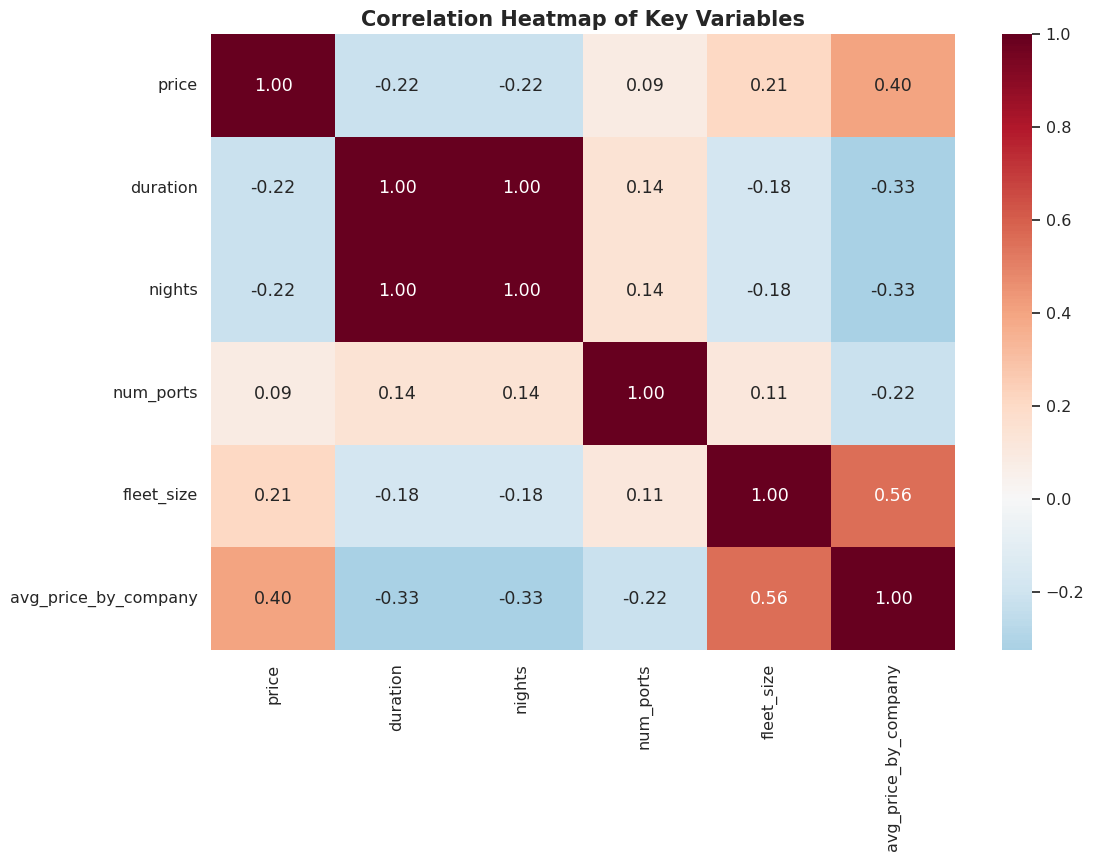

In [ ]:
# CORRELATION
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

numeric_df = df.select_dtypes(include=['number'])
corr_matrix = numeric_df.corr()
features = ['price', 'duration', 'nights', 'num_ports', 'fleet_size', 'avg_price_by_company']

# Plot
plt.figure(figsize=(12, 8))
corr_matrix = df[features].corr()
sns.heatmap(corr_matrix, annot=True, cmap='RdBu_r', center=0, fmt=".2f")

plt.title('Correlation Heatmap of Key Variables', fontsize=15)
plt.savefig('correlation_heatmap.png')
plt.show()

In [ ]:
display_cols = ['name', 'company', 'ship', 'duration', 'price', 'price_per_night', 'region', 'season']
display_cols = [c for c in display_cols if c in df.columns]

print(' TOP 5 MOST EXPENSIVE Cruises (by price per night):')
display(df.nlargest(5, 'price_per_night')[display_cols].reset_index(drop=True))

print('\n TOP 5 MOST AFFORDABLE Cruises (by price per night):')
display(df.nsmallest(5, 'price_per_night')[display_cols].reset_index(drop=True))

print('\n TOP 5 LONGEST Cruises:')
display(df.nlargest(5, 'duration')[display_cols].reset_index(drop=True))


 TOP 5 MOST EXPENSIVE Cruises (by price per night):


,name,company,ship,duration,price,price_per_night,region,season
0,"1 night in Spain, France",MSC Yacht Club,MSC Yacht Club Grandiosa,1,489,489.0,Mediterranean,Spring
1,"2 nights in Marseille, Genoa and Naples.",MSC Yacht Club,MSC Yacht Club World Europa,2,909,454.5,Mediterranean,Summer
2,2 nights in UK and France,MSC Yacht Club,MSC Yacht Club Virtuosa,2,899,449.5,Other,Spring
3,"1 night in Rio de Janeiro, Santos",MSC Yacht Club,MSC Yacht Club Divina,1,449,449.0,Other,Autumn
4,"1 night in Santos, Rio de Janeiro.",MSC Yacht Club,MSC Yacht Club Divina,1,449,449.0,Other,Spring



 TOP 5 MOST AFFORDABLE Cruises (by price per night):


,name,company,ship,duration,price,price_per_night,region,season
0,"50 nights in Sydney, Noumea, Luganville, Apia,...",MSC Cruises,MSC Magnifica,50,6,0.120000,Other,Spring
1,"121 nights Genoa, Marseille, Barcelona, ​​Gibr...",MSC Cruises,MSC Magnifica,121,15,0.123967,Mediterranean,Winter
2,"121 nights Spain, Gibraltar, Morocco, Cape Ver...",MSC Cruises,MSC Magnifica,121,15,0.123967,Mediterranean,Winter
3,"132 nights Genoa, Marseille, Barcelona, ​​Gibr...",MSC Cruises,MSC Magnifica,132,17,0.128788,Mediterranean,Winter
4,"121 nights Marseille, Barcelona, ​​Gibraltar, ...",MSC Cruises,MSC Magnifica,121,16,0.132231,Mediterranean,Winter



 TOP 5 LONGEST Cruises:


,name,company,ship,duration,price,price_per_night,region,season
0,An epic global adventure,Oceania Cruises,VISTA,244,108,0.442623,Other,Winter
1,188 nights from San Francisco,Azamara Cruises,Azamara Quest,188,65,0.345745,Other,Winter
2,Around the world in 180 days,Oceania Cruises,VISTA,180,77,0.427778,Other,Winter
3,"132 nights Genoa, Marseille, Barcelona, ​​Gibr...",MSC Cruises,MSC Magnifica,132,17,0.128788,Mediterranean,Winter
4,Kangaroo Route,Oceania Cruises,VISTA,129,54,0.418605,Other,Winter


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import warnings
warnings.filterwarnings('ignore')
PALETTE = {
    'primary':    '#2F6FED',  # clean blue (trustworthy, not dark)
    'secondary':  '#4FB3D9',  # light sky blue
    'accent':     '#F4A261',  # soft orange
    'success':    '#2A9D8F',  # teal green
    'warning':    '#E9C46A',  # soft yellow
    'danger':     '#E76F51',  # soft red (not aggressive)
    'neutral':    '#8A8A8A',  # balanced gray
    'background': '#F7F9FC'   # very light clean background
}
SEASON_COLORS  = {'Spring':'#27AE60','Summer':'#F4D03F','Autumn':'#E8743B','Winter':'#2C3E7A'}
SEGMENT_COLORS = {'Budget':'#27AE60','Mid-range':'#E8743B','Luxury':'#E74C3C'}
REGION_COLORS  = {'Mediterranean':'#2C3E7A','USA':'#E8743B','Northern Europe':'#27AE60',
                  'Middle East':'#E74C3C','Other':'#95A5A6'}

sns.set_theme(style='whitegrid', font_scale=1.05)
plt.rcParams.update({
    'font.family':      'DejaVu Sans',
    'axes.titleweight': 'bold',
    'axes.titlesize':   13,
    'axes.labelsize':   11,
    'figure.facecolor': 'white',
})


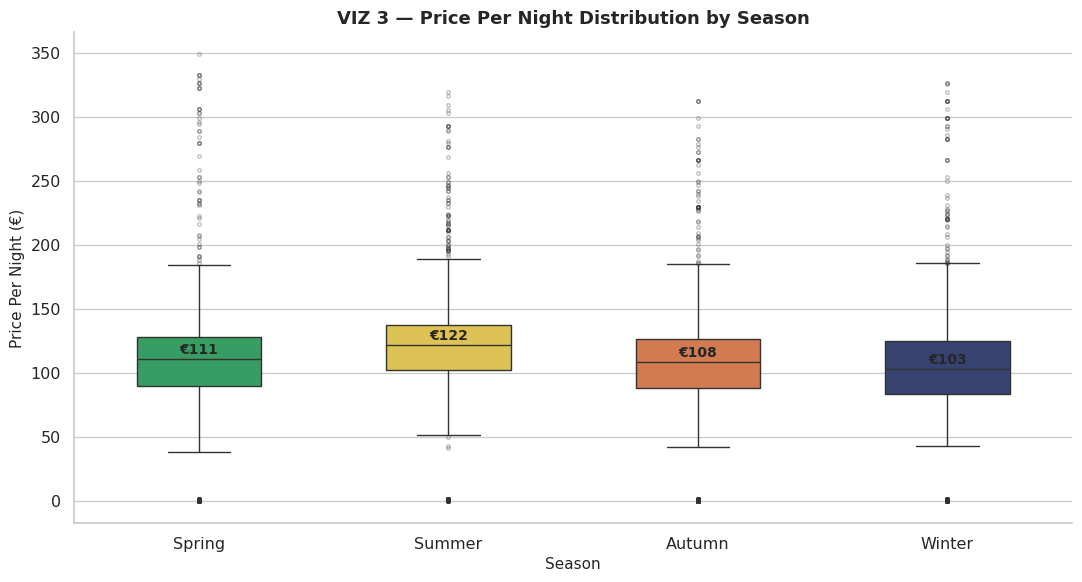

In [ ]:
# ══════════════════════════════════════════════════════════════
# VIZ 4 — BOX PLOT  (static, Seaborn)
# Price Per Night by Season — full distribution comparison
# ══════════════════════════════════════════════════════════════

season_order = ['Spring','Summer','Autumn','Winter']
plot_data    = df[df['price_per_night'] < 350]

fig, ax = plt.subplots(figsize=(11, 6))
sns.boxplot(data=plot_data, x='season', y='price_per_night',
            order=season_order,
            palette=SEASON_COLORS,
            width=0.5, fliersize=2.5,
            flierprops=dict(alpha=0.3),
            ax=ax)

# Annotate medians
for i, season in enumerate(season_order):
    med = plot_data[plot_data['season']==season]['price_per_night'].median()
    ax.text(i, med + 4, f'€{med:.0f}',
            ha='center', fontsize=10, fontweight='bold')

ax.set_xlabel('Season')
ax.set_ylabel('Price Per Night (€)')
ax.set_title('VIZ 3 — Price Per Night Distribution by Season')
ax.spines[['top','right']].set_visible(False)

plt.tight_layout()
plt.savefig('viz03_boxplot_season.png', dpi=150, bbox_inches='tight')
plt.show()

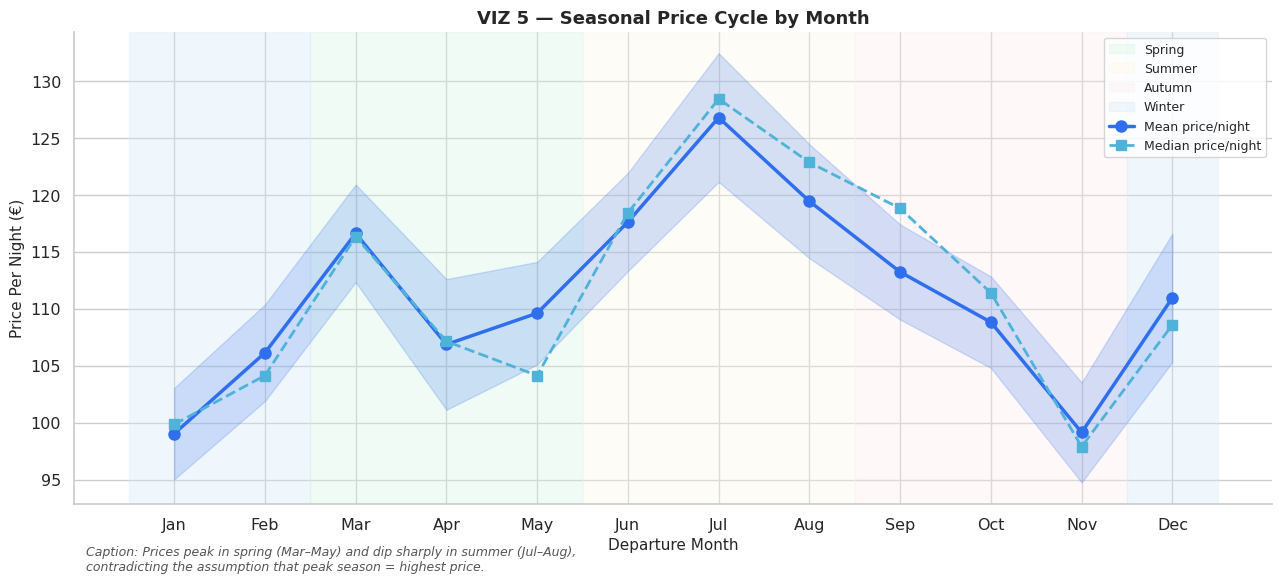

In [ ]:
# ══════════════════════════════════════════════════════════════
# VIZ 5 — LINE CHART  (static, Matplotlib)
# Monthly seasonal price cycle with shaded season bands
# ══════════════════════════════════════════════════════════════

month_stats = df.groupby('departure_month')['price_per_night'].agg(
    ['mean','median','std','count']).reset_index()
month_stats['ci95'] = 1.96 * month_stats['std'] / np.sqrt(month_stats['count'])
month_names = ['Jan','Feb','Mar','Apr','May','Jun',
               'Jul','Aug','Sep','Oct','Nov','Dec']

fig, ax = plt.subplots(figsize=(13, 6))

# Season bands
for start, end, color, label in [
    (3,5,'#D5F5E3','Spring'),(6,8,'#FEF9E7','Summer'),
    (9,11,'#FDEDEC','Autumn'),(12,12,'#D6EAF8','Winter')]:
    ax.axvspan(start-0.5, end+0.5, alpha=0.35, color=color, label=label)
ax.axvspan(0.5, 2.5, alpha=0.35, color='#D6EAF8')  # Jan–Feb Winter

# Mean line + CI ribbon
ax.fill_between(month_stats['departure_month'],
                month_stats['mean'] - month_stats['ci95'],
                month_stats['mean'] + month_stats['ci95'],
                alpha=0.2, color=PALETTE['primary'])
ax.plot(month_stats['departure_month'], month_stats['mean'],
        'o-', color=PALETTE['primary'],
        linewidth=2.5, markersize=8, label='Mean price/night')
ax.plot(month_stats['departure_month'], month_stats['median'],
        's--', color=PALETTE['secondary'],
        linewidth=2, markersize=7, label='Median price/night')

ax.set_xticks(range(1,13))
ax.set_xticklabels(month_names)
ax.set_ylabel('Price Per Night (€)')
ax.set_xlabel('Departure Month')
ax.set_title('VIZ 5 — Seasonal Price Cycle by Month')
ax.legend(loc='upper right', fontsize=9)
ax.spines[['top','right']].set_visible(False)

ax.text(0.01, -0.14,
    "Caption: Prices peak in spring (Mar–May) and dip sharply in summer (Jul–Aug),\n"
    "contradicting the assumption that peak season = highest price.",
    transform=ax.transAxes, fontsize=9, color='#555', style='italic')

plt.tight_layout()
plt.savefig('viz05_line_seasonal.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
# VIS 10
month_names_list = ['Jan','Feb','Mar','Apr','May','Jun',
                    'Jul','Aug','Sep','Oct','Nov','Dec']

df_clean = df[df['price_per_night'] >= 10].copy()

monthly_fig = (
    df_clean.groupby('departure_month')
      .agg(avg_ppn=('price_per_night', 'mean'),
           median_ppn=('price_per_night', 'median'),
           count=('price', 'count'))
      .reset_index()
      .round(1)
)
monthly_fig['month_name'] = monthly_fig['departure_month'].apply(lambda x: month_names_list[x-1])

fig = go.Figure()
fig.add_trace(go.Bar(
    x=monthly_fig['month_name'],
    y=monthly_fig['avg_ppn'],
    name='Avg Price/Night',
    marker_color=monthly_fig['avg_ppn'],
    marker_colorscale='Oranges',
    text=monthly_fig['avg_ppn'].apply(lambda x: f'${x:.0f}'),
    textposition='outside',
    hovertemplate='%{x}<br>Avg: $%{y:.0f}/night<br>Cruises: %{customdata}',
    customdata=monthly_fig['count']
))
fig.add_trace(go.Scatter(
    x=monthly_fig['month_name'],
    y=monthly_fig['median_ppn'],
    mode='lines+markers',
    name='Median Price/Night',
    line={'color': '#264653', 'width': 2.5, 'dash': 'dot'},
    marker={'size': 8}
))
fig.update_layout(
    xaxis_title='Month',
    yaxis_title='Price per Night ($)',
    height=500,
    plot_bgcolor='white',
    legend={'orientation': 'h', 'y': 1.12},
    bargap=0.2
)
fig.update_yaxes(showgrid=True, gridcolor='#eee')
fig.show()

📌 Caption: Darker orange months are the priciest to cruise.
   When the average (bar) is much taller than the median (dot), luxury cruises are skewing that month.


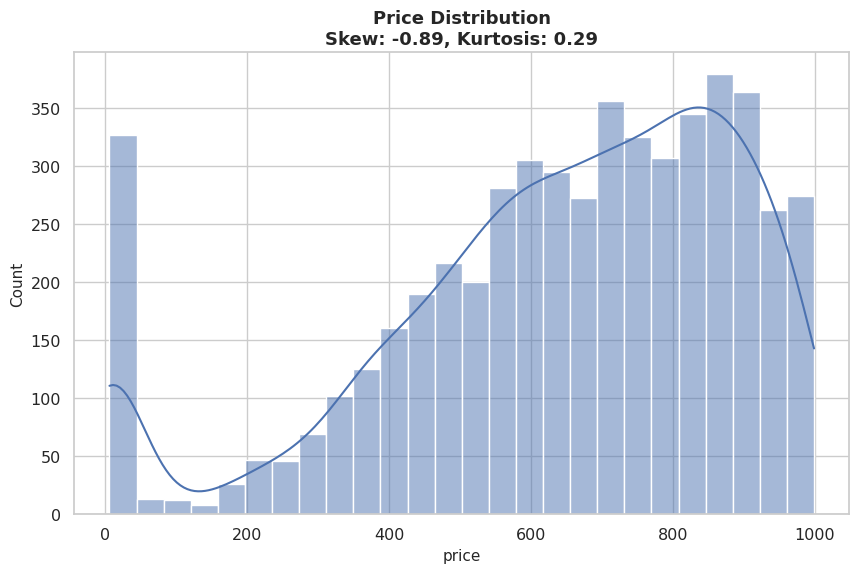

In [ ]:
# DISTRIBUTION
from scipy.stats import skew, kurtosis, normaltest
price_skew = df['price'].skew()
price_kurt = df['price'].kurtosis()

stat, p = normaltest(df['price'])

plt.figure(figsize=(10, 6))
sns.histplot(df['price'], kde=True)
plt.title(f'Price Distribution\nSkew: {price_skew:.2f}, Kurtosis: {price_kurt:.2f}')
plt.savefig('price_dist.png')

In [ ]:
# VIS 11
import plotly.express as px
import plotly.graph_objects as go
import pandas as pd

# ── Region coordinates (center points on the map) ────────────
region_coords = {
    'Mediterranean':   {'lat': 41.0,  'lon': 15.0},
    'USA':             {'lat': 25.0,  'lon': -80.0},
    'Northern Europe': {'lat': 60.0,  'lon': 10.0},
    'Middle East':     {'lat': 24.0,  'lon': 55.0},
    'Other':           {'lat': 10.0,  'lon': -30.0},
}

# ── Region → ISO country codes (for filled borders) ──────────
region_countries = {
    'Mediterranean':   ['ITA', 'ESP', 'GRC', 'HRV', 'FRA', 'TUR', 'MLT', 'MNE'],
    'USA':             ['USA'],
    'Northern Europe': ['NOR', 'ISL', 'DNK', 'SWE', 'FIN', 'GBR', 'IRL', 'EST'],
    'Middle East':     ['ARE', 'OMN', 'SAU', 'BHR', 'QAT', 'JOR', 'ISR'],
    'Other':           ['JPN', 'BHS', 'DOM', 'BRA', 'AUS', 'MEX', 'CHL'],
}

region_colors = {
    'Mediterranean':   '#E63946',
    'USA':             '#457B9D',
    'Northern Europe': '#2A9D8F',
    'Middle East':     '#E9C46A',
    'Other':           '#F4A261',
}

# ── Build summary table per region ───────────────────────────
df_clean = df[df['price_per_night'] >= 10].copy()

region_summary = df_clean.groupby('region').agg(
    total_cruises   = ('price', 'count'),
    avg_price_night = ('price_per_night', 'mean'),
    avg_duration    = ('duration', 'mean'),
).reset_index().round(1)

# Attach coordinates
region_summary['lat'] = region_summary['region'].map(lambda r: region_coords[r]['lat'])
region_summary['lon'] = region_summary['region'].map(lambda r: region_coords[r]['lon'])

# Friendly label shown on hover
region_summary['label'] = (
    region_summary['region'] +
    '<br>Cruises: '          + region_summary['total_cruises'].astype(str) +
    '<br>Avg Price/Night: €' + region_summary['avg_price_night'].astype(str) +
    '<br>Avg Duration: '     + region_summary['avg_duration'].astype(str) + ' nights'
)

# ── Build choropleth layer (filled countries) ─────────────────
iso_list    = []
color_list  = []
region_list = []

for region, isos in region_countries.items():
    for iso in isos:
        iso_list.append(iso)
        color_list.append(region_colors[region])
        region_list.append(region)

choropleth = go.Choropleth(
    locations         = iso_list,
    z                 = [list(region_colors.keys()).index(r) for r in region_list],
    colorscale        = [[i/4, c] for i, c in enumerate(region_colors.values())],
    showscale         = False,
    marker_line_color = 'white',
    marker_line_width = 0.8,
    hoverinfo         = 'skip',
)

# ── Build bubble layer ────────────────────────────────────────
scatter = px.scatter_geo(
    region_summary,
    lat='lat',
    lon='lon',
    size='total_cruises',
    color='avg_price_night',
    color_continuous_scale=[
        [0.0, '#27AE60'],
        [0.5, '#F39C12'],
        [1.0, '#E74C3C'],
    ],
    hover_name='label',
    size_max=60,
    projection='natural earth',
).data[0]

# ── Combine both layers ───────────────────────────────────────
fig = go.Figure(data=[choropleth, scatter])

# ── Styling ───────────────────────────────────────────────────
fig.update_traces(
    hovertemplate='%{hovertext}<extra></extra>',
    marker=dict(opacity=0.85, line=dict(width=2, color='white')),
    selector=dict(type='scattergeo')
)

fig.update_layout(
    title=dict(
        text='Where Can You Go on a Cruise?<br>'
             '<sup>Bigger bubble = more cruises available  |  '
             'Green = cheap     Orange = medium     Red = expensive</sup>',
        font=dict(size=18, family='Arial'),
        x=0.5
    ),
    coloraxis_colorbar=dict(
        title='Avg Price<br>Per Night (€)',
        tickprefix='€',
        thickness=15,
        len=0.6,
    ),
    geo=dict(
        showland=True,       landcolor='#F0F4F8',
        showocean=True,      oceancolor='#D6EAF8',
        showcoastlines=True, coastlinecolor='#AAB7C4',
        showcountries=True,  countrycolor='#D0D5DE',
        showframe=False,
        projection_scale=1.1,
    ),
    paper_bgcolor='white',
    margin=dict(l=0, r=0, t=80, b=0),
    width=950, height=550,
)

fig.write_html('viz_geographic_map.html')
fig.show()

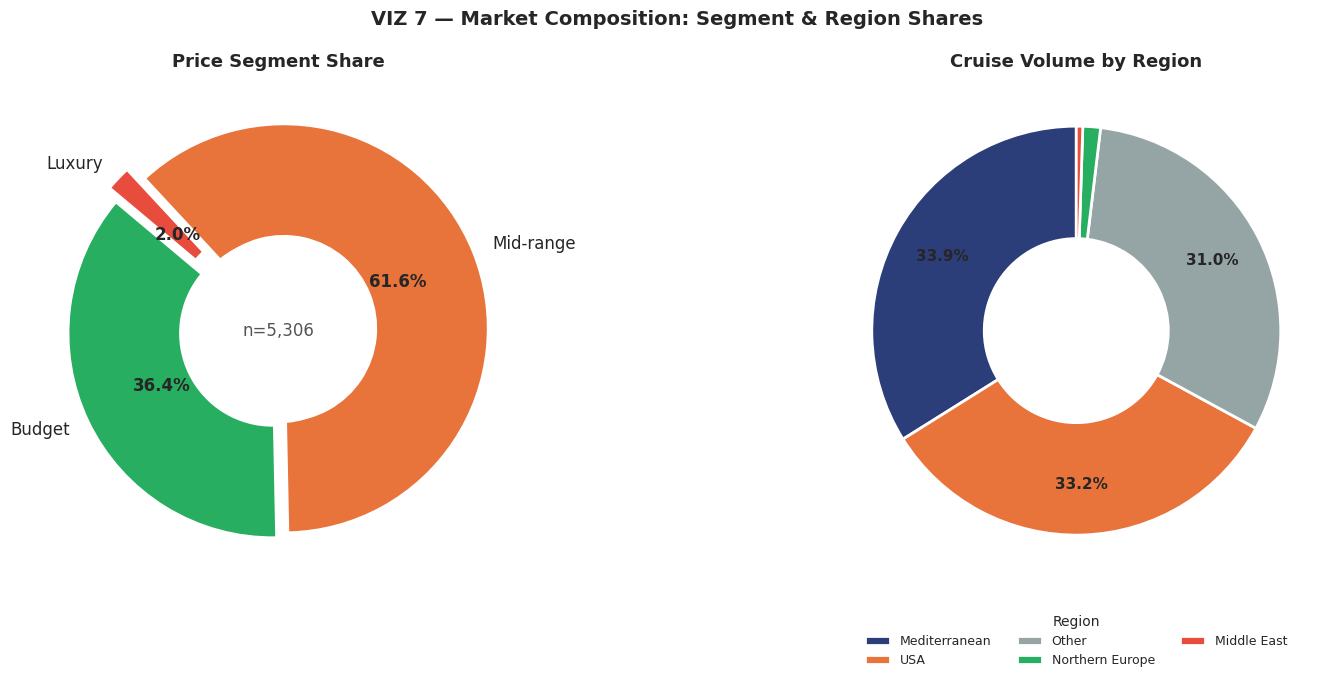

In [ ]:
# ══════════════════════════════════════════════════════════════
# VIZ 7 — PIE / DONUT CHART  (static, Matplotlib)
# Price Segment share — with region breakdown inner ring
# ══════════════════════════════════════════════════════════════

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Left — Price Segment donut
seg = df['price_segment'].value_counts().reindex(['Budget','Mid-range','Luxury'])
wedge_colors = [SEGMENT_COLORS[s] for s in seg.index]

wedges, texts, autos = axes[0].pie(
    seg, labels=seg.index, autopct='%1.1f%%',
    colors=wedge_colors,
    explode=[0.03,0.03,0.08],
    startangle=140,
    wedgeprops=dict(width=0.55, edgecolor='white', linewidth=2),
    textprops={'fontsize': 12})

for at in autos: at.set_fontweight('bold')
axes[0].add_patch(plt.Circle((0,0), 0.45, fc='white'))
axes[0].text(0, 0, f'n={len(df):,}', ha='center', va='center',
             fontsize=12, color='#555')
axes[0].set_title('Price Segment Share')

# Right — Region donut
reg = df['region'].value_counts()
reg_colors = [REGION_COLORS.get(r, PALETTE['neutral']) for r in reg.index]

wedges2, texts2, autos2 = axes[1].pie(
    reg,
    autopct=lambda pct: f'{pct:.1f}%' if pct > 4 else '',
    colors=reg_colors,
    startangle=90,
    wedgeprops=dict(width=0.55, edgecolor='white', linewidth=2),
    textprops={'fontsize': 11},
    pctdistance=0.75)

for at in autos2: at.set_fontweight('bold')
axes[1].add_patch(plt.Circle((0,0), 0.45, fc='white'))
axes[1].set_title('Cruise Volume by Region')

axes[1].legend(
    wedges2, reg.index,
    title='Region',
    loc='lower center',
    bbox_to_anchor=(0.5, -0.18),
    ncol=3,
    fontsize=9,
    title_fontsize=10,
    frameon=False)

fig.suptitle('VIZ 7 — Market Composition: Segment & Region Shares',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('viz07_donut_segments.png', dpi=150, bbox_inches='tight')
plt.show()



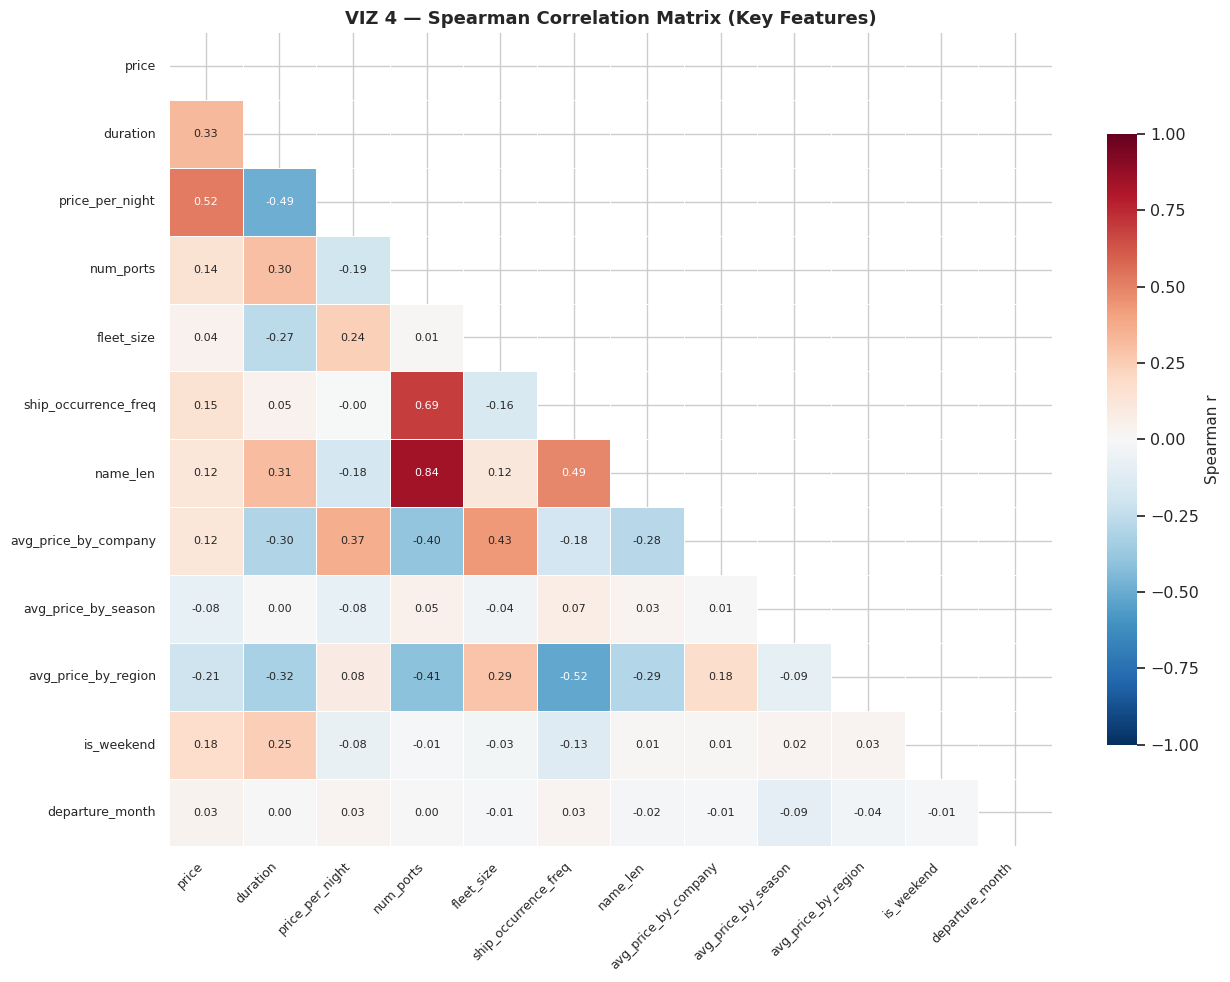

In [ ]:
# ══════════════════════════════════════════════════════════════
# VIZ 4 — HEATMAP  (static, Seaborn)
# Correlation matrix of key numerical features
# ══════════════════════════════════════════════════════════════

from scipy.stats import spearmanr

num_cols = ['price','duration','price_per_night','num_ports',
            'fleet_size','ship_occurrence_freq','name_len',
            'avg_price_by_company','avg_price_by_season',
            'avg_price_by_region','is_weekend','departure_month']

corr  = df[num_cols].corr(method='spearman')
mask  = np.triu(np.ones_like(corr, dtype=bool))

fig, ax = plt.subplots(figsize=(13, 10))
sns.heatmap(corr, mask=mask,
            annot=True, fmt='.2f', cmap='RdBu_r',
            center=0, vmin=-1, vmax=1,
            linewidths=0.4, linecolor='white',
            annot_kws={'size': 8}, ax=ax,
            cbar_kws={'shrink': 0.75, 'label': 'Spearman r'})

ax.set_title('VIZ 4 — Spearman Correlation Matrix (Key Features)')
plt.xticks(rotation=45, ha='right', fontsize=9)
plt.yticks(rotation=0,  fontsize=9)

plt.tight_layout()
plt.savefig('viz04_heatmap_correlation.png', dpi=150, bbox_inches='tight')
plt.show()

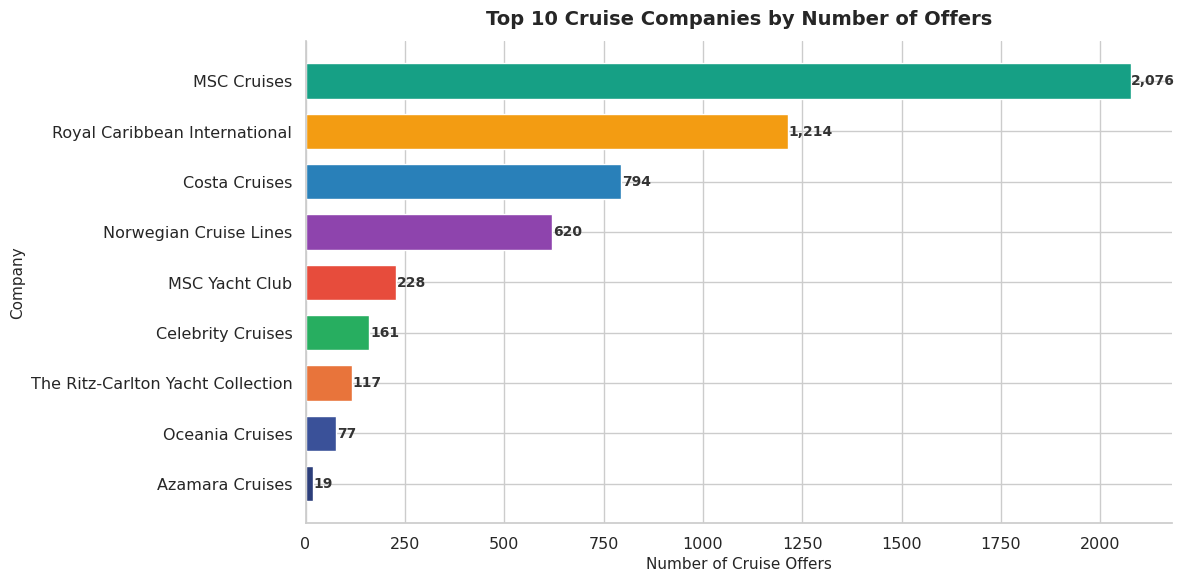

📌 Caption: The market is dominated by a handful of companies. The top company offers far more
   cruises than the rest, suggesting strong market concentration.


In [ ]:
# ══════════════════════════════════════════════════════════════
# VIZ 1 — Top 10 Cruise Companies by Number of Offers
# ══════════════════════════════════════════════════════════════

COLORS = [
    '#2C3E7A','#3A5199','#E8743B','#27AE60','#E74C3C',
    '#8E44AD','#2980B9','#F39C12','#16A085','#95A5A6'
]

top_companies = df['company'].value_counts().head(10)
fig, ax = plt.subplots(figsize=(12, 6))
bars = ax.barh(top_companies.index[::-1], top_companies.values[::-1],
               color=COLORS[:len(top_companies)], edgecolor='white', height=0.7)
# Add value labels at the end of each bar
for bar in bars:
    w = bar.get_width()
    ax.text(w + 2, bar.get_y() + bar.get_height()/2, f'{int(w):,}',
            va='center', fontsize=10, fontweight='bold', color='#333')
ax.set_title('Top 10 Cruise Companies by Number of Offers', fontsize=14, fontweight='bold', pad=12)
ax.set_xlabel('Number of Cruise Offers')
ax.set_ylabel('Company')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig('fig03_top_companies_bar.png', bbox_inches='tight')
plt.show()
print('📌 Caption: The market is dominated by a handful of companies. The top company offers far more')
print('   cruises than the rest, suggesting strong market concentration.')

In [ ]:
# ══════════════════════════════════════════════════════════════
# VIZ 12 — INTERACTIVE BAR  (Plotly)  ← Interactive #2
# Avg Price/Night by Region × Season — grouped & filterable
# ══════════════════════════════════════════════════════════════
# Check how many cruises exist per season in Middle East
print(df[df['region'] == 'Middle East']['season'].value_counts())

# Check the actual avg price/night per season for Middle East
print(df[df['region'] == 'Middle East']
      .groupby('season')['price_per_night']
      .agg(['mean', 'count']))

region_season = (df.groupby(['region','season'])['price_per_night']
                   .agg(['mean','median','count'])
                   .reset_index()
                   .rename(columns={'mean':'avg','median':'med','count':'n'}))

fig12 = px.bar(
    region_season,
    x='region', y='avg',
    color='season',
    color_discrete_map=SEASON_COLORS,
    barmode='group',
    hover_data={'med':':.2f','n':True,'avg':':.2f'},
    labels={'avg':'Avg Price/Night (€)','region':'Region','season':'Season'},
    title='VIZ (Interactive) — Avg Price/Night by Region & Season<br>',
    category_orders={'season':['Spring','Summer','Autumn','Winter']}
)
fig12.update_layout(
    font_family='Arial', plot_bgcolor='white',
    legend_title_text='Season',
    xaxis_title='Region', yaxis_title='Avg Price Per Night (€)',
    xaxis=dict(showgrid=False),
    yaxis=dict(showgrid=True, gridcolor='#ECF0F1'),
)

fig12.write_html('viz12_interactive_grouped_bar.html')
fig12.show()

season
Spring    14
Winter    10
Autumn     3
Name: count, dtype: int64
             mean  count
season                  
Autumn  91.761905      3
Spring  64.458722     14
Winter  84.571429     10


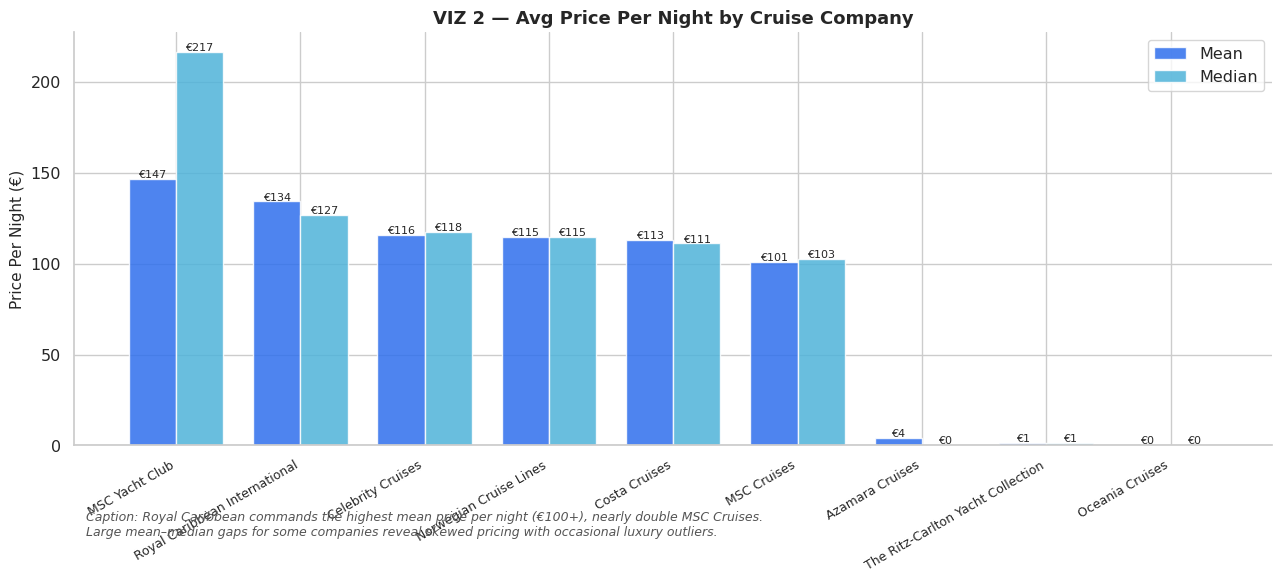

In [ ]:
# VIZ 3 — BAR CHART  (static, Seaborn)
# Average Price Per Night by Company — mean + median side by side

comp_stats = (df.groupby('company')['price_per_night']
                .agg(['mean','median'])
                .sort_values('mean', ascending=False)
                .reset_index())

x     = np.arange(len(comp_stats))
width = 0.38

fig, ax = plt.subplots(figsize=(13, 6))
ax.bar(x - width/2, comp_stats['mean'],   width,
       color=PALETTE['primary'],    alpha=0.85,
       edgecolor='white', label='Mean')
ax.bar(x + width/2, comp_stats['median'], width,
       color=PALETTE['secondary'],  alpha=0.85,
       edgecolor='white', label='Median')

for i, row in comp_stats.iterrows():
    ax.text(i - width/2, row['mean']   + 0.5,
            f"€{row['mean']:.0f}",   ha='center', fontsize=8)
    ax.text(i + width/2, row['median'] + 0.5,
            f"€{row['median']:.0f}", ha='center', fontsize=8)

ax.set_xticks(x)
ax.set_xticklabels(comp_stats['company'],
                   rotation=30, ha='right', fontsize=9)
ax.set_ylabel('Price Per Night (€)')
ax.set_title('VIZ 2 — Avg Price Per Night by Cruise Company')
ax.legend()
ax.spines[['top','right']].set_visible(False)

ax.text(0.01, -0.22,
    "Caption: Royal Caribbean commands the highest mean price per night (€100+), nearly double MSC Cruises.\n"
    "Large mean–median gaps for some companies reveal skewed pricing with occasional luxury outliers.",
    transform=ax.transAxes, fontsize=9, color='#555', style='italic')

plt.tight_layout()
plt.savefig('viz02_bar_company_price.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
# ══════════════════════════════════════════════════════════════
# VIZ 13 — INTERACTIVE HEATMAP  (Plotly)  ← Interactive #3
# Month × Day-of-Week price heatmap — zoomable, hoverable
# ══════════════════════════════════════════════════════════════

month_names_short = ['Jan','Feb','Mar','Apr','May','Jun',
                     'Jul','Aug','Sep','Oct','Nov','Dec']
dow_names         = ['Mon','Tue','Wed','Thu','Fri','Sat','Sun']

heat = df.pivot_table(values='price_per_night',
                      index='departure_day_of_week',
                      columns='departure_month',
                      aggfunc='mean').round(2)
heat.index   = [dow_names[i] for i in heat.index]
heat.columns = [month_names_short[m-1] for m in heat.columns]

fig13 = go.Figure(data=go.Heatmap(
    z=heat.values,
    x=heat.columns,
    y=heat.index,
    colorscale='YlOrRd',
    hoverongaps=False,
    hovertemplate='Month: %{x}<br>Day: %{y}<br>Avg €%{z:.2f}/night<extra></extra>',
    colorbar=dict(title='Avg Price/Night (€)')
))
fig13.update_layout(
    title=dict(
        text='VIZ(Interactive) — Avg Price/Night: Month × Day of Week<br>',
        font_size=14),
    xaxis_title='Month',
    yaxis_title='Day of Week',
    font_family='Arial',
    width=900, height=480
)
fig13.write_html('viz13_interactive_heatmap.html')
fig13.show()